# Klassifikation

## Präambel

Wir laden alle Pakete und Module, die wir im Folgenden benötigen.

In [1]:
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

import itertools

from sklearn.datasets import load_iris
from sklearn import tree
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import normalize
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from mlxtend.classifier import EnsembleVoteClassifier
from mlxtend.plotting import plot_decision_regions

import tensorflow as tf # Ignoriere die CUDA-Warnungen (wir verwenden keine Grafikkarte)

2024-10-18 10:51:32.945007: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2024-10-18 10:51:32.949854: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2024-10-18 10:51:32.964852: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-18 10:51:32.992535: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-18 10:51:33.000223: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-18 10:51:34.460256: W tensorflow/compiler/tf2tensorrt/utils/p

## Daten

Der Iris-Datensatz ist ein beliebter Beispieldatensatz. Er enthält vier Merkmale:

* Länge der Kelchblätter (Sepalen, engl. sepal)
* Breite der Kelchblätter
* Länge der Kronblätter (Petalen, engl. petal)
* Breite der Kronblätter

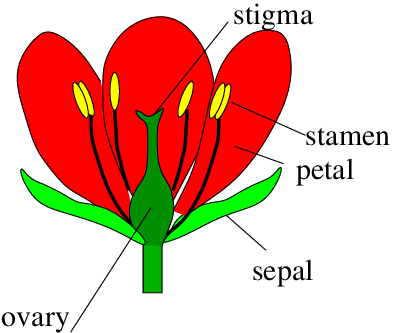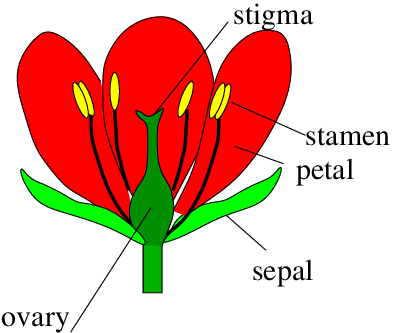

In [2]:
# Lade die Iris-Daten
iris = load_iris()

# Speichere den Input-Datensatz unter X
X = iris.data
# und die Klasse unter y
y = iris.target

### Ein Blick auf die Daten

In [3]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [4]:
# Zeige X
X

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [5]:
# Wir beschränken uns auf die 1. und 3. Spalte des Datensatzes
X = X[:,[0, 2]]

In [6]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [7]:
# Zeige y
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

### Visualisiere die Daten

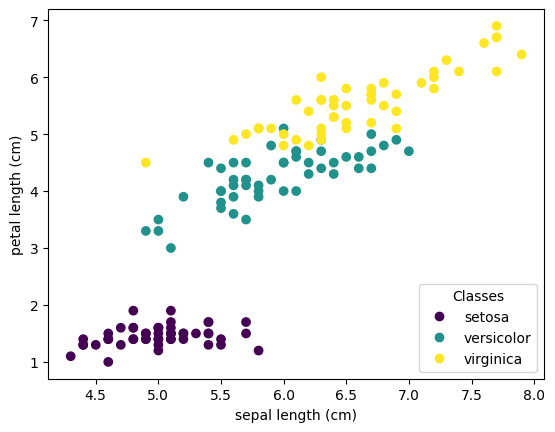

In [8]:
# Generiere eine leere Grafik
fig, ax = plt.subplots()

# Erstelle den Scatterplot
scatter = ax.scatter(x = X[:, 0],
                     y = X[:, 1],
                     c = y)

# Benenne die Achsen
ax.set(xlabel=iris.feature_names[0], ylabel=iris.feature_names[2])

# Füge Legende hinzu
ax.legend(scatter.legend_elements()[0], iris.target_names, loc="lower right", title="Classes")

## Decision tree

In [10]:
# Generiere ein "leeres" Modell
dcsntree = tree.DecisionTreeClassifier(random_state=0)

In [11]:
# Zeige Ergebnis an
dcsntree

DecisionTreeClassifier(random_state=0)

In [12]:
# Trainiere das Modell mit den Daten
dcsntree.fit(X, y)

DecisionTreeClassifier(random_state=0)

In [13]:
# Zeige Ergebnis an
dcsntree

DecisionTreeClassifier(random_state=0)

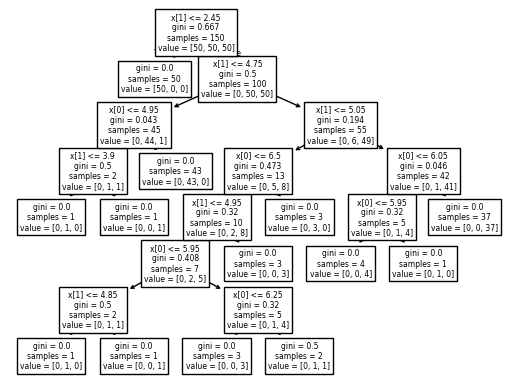

In [15]:
# Zeige den Entscheidungsbaum
tree.plot_tree(dcsntree);

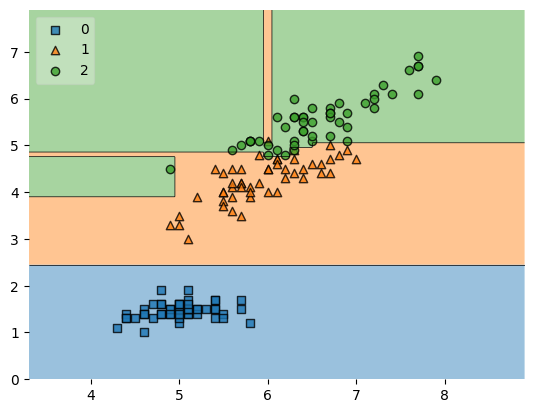

In [16]:
# Zeige die Vorhersagen
fig = plt.figure()
ax = plt.subplot()
fig = plot_decision_regions(X=X, y=y, clf = dcsntree, legend = 2)

In [17]:
confusion_matrix = metrics.confusion_matrix(y, dcsntree.predict(X))
confusion_matrix

array([[50,  0,  0],
       [ 0, 50,  0],
       [ 0,  1, 49]])

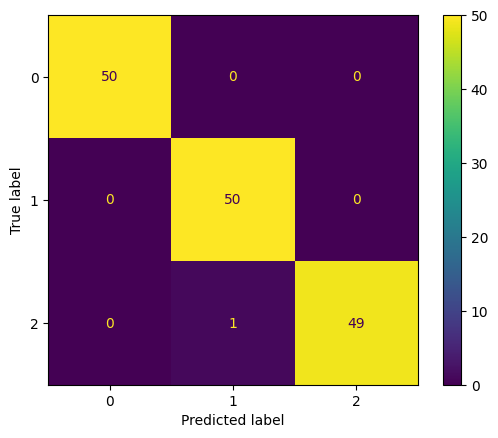

In [18]:
plot_confusion_matrix = metrics.ConfusionMatrixDisplay(confusion_matrix)
plot_confusion_matrix.plot()

## Lazy learners (Beispiel KNN)

In [19]:
# Generiere ein "leeres" Modell
knn = KNeighborsClassifier(n_neighbors=1)

# Trainiere das Modell mit den Daten
knn = knn.fit(X, y)

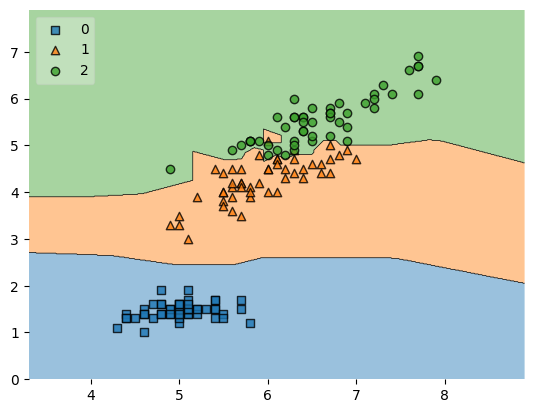

In [20]:
fig = plt.figure()
ax = plt.subplot()
fig = plot_decision_regions(X=X, y=y, clf = knn, legend = 2)

In [21]:
confusion_matrix = metrics.confusion_matrix(y, knn.predict(X))
confusion_matrix

array([[50,  0,  0],
       [ 0, 49,  1],
       [ 0,  0, 50]])

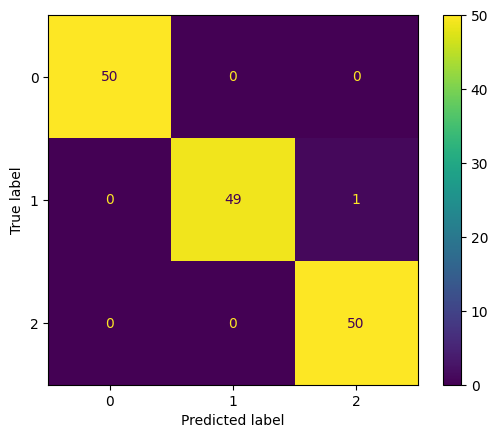

In [22]:
plot_confusion_matrix = metrics.ConfusionMatrixDisplay(confusion_matrix)
plot_confusion_matrix.plot()

## Linear classifiers (Beispiel Logistic Regression)

In [23]:
# Generiere ein "leeres" Modell
logreg_res = LogisticRegression(random_state=0)

# Trainiere das Modell mit den Daten
logreg_res = logreg_res.fit(X, y)

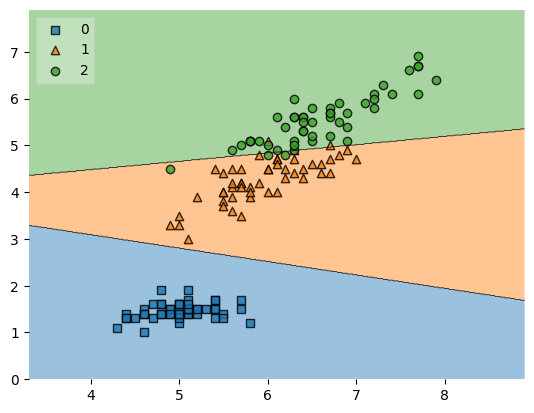

In [24]:
fig = plt.figure()
ax = plt.subplot()
fig = plot_decision_regions(X=X, y=y, clf = logreg_res, legend = 2)

In [25]:
confusion_matrix = metrics.confusion_matrix(y, logreg_res.predict(X))
confusion_matrix

array([[50,  0,  0],
       [ 0, 47,  3],
       [ 0,  3, 47]])

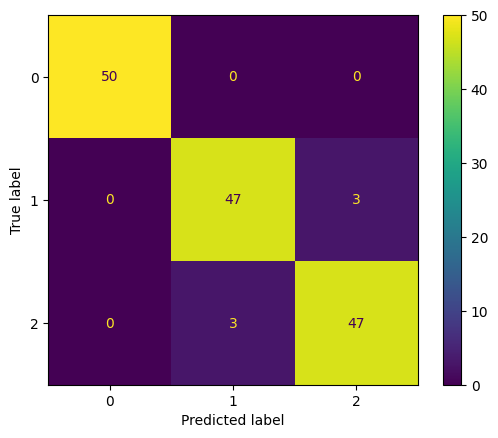

In [26]:
plot_confusion_matrix = metrics.ConfusionMatrixDisplay(confusion_matrix)
plot_confusion_matrix.plot()

## Support vector machine (SVM)

In [27]:
# Generiere ein "leeres" Modell
svm_res = SVC(random_state=0, probability=True)

# Trainiere das Modell mit den Daten
svm_res = svm_res.fit(X, y)

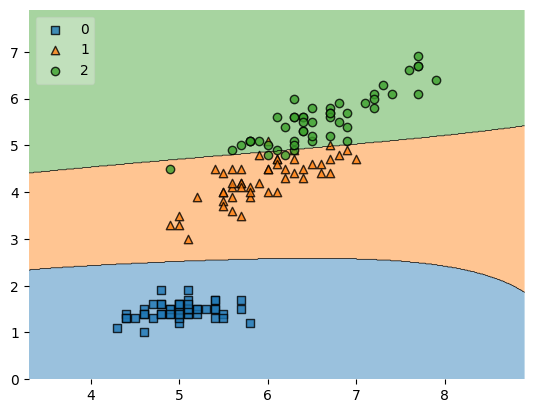

In [28]:
fig = plt.figure()
ax = plt.subplot()
fig = plot_decision_regions(X=X, y=y, clf = svm_res, legend = 2)

In [29]:
confusion_matrix = metrics.confusion_matrix(y, svm_res.predict(X))
confusion_matrix

array([[50,  0,  0],
       [ 0, 48,  2],
       [ 0,  4, 46]])

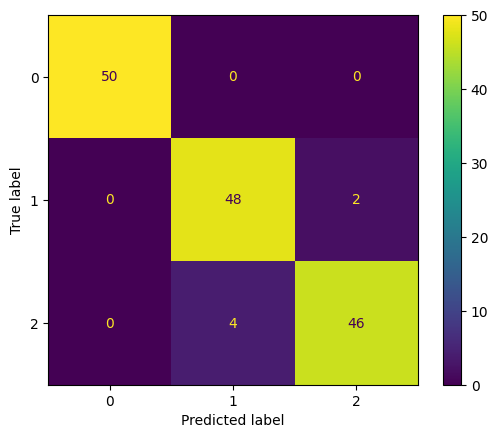

In [30]:
plot_confusion_matrix = metrics.ConfusionMatrixDisplay(confusion_matrix)
plot_confusion_matrix.plot()

## Ensembles

Manche Modelle können bestimmte Gruppen besser erkennen als andere. Daher hat es sich bewährt, für bestimmte Gruppen Spezialmodelle zu entwickeln, die dann mithilfe eines Metamodells miteinander verbunden werden. Solche Modelle werden auch als Ensembles bezeichnet.

### Random Forest

Ein Random Forest ist eine Sammlung mehrerer Decision Trees.

In [31]:
# Generiere ein "leeres" Modell
randfor_res = RandomForestClassifier(random_state=0)

# Trainiere das Modell mit den Daten
randfor_res = randfor_res.fit(X, y)

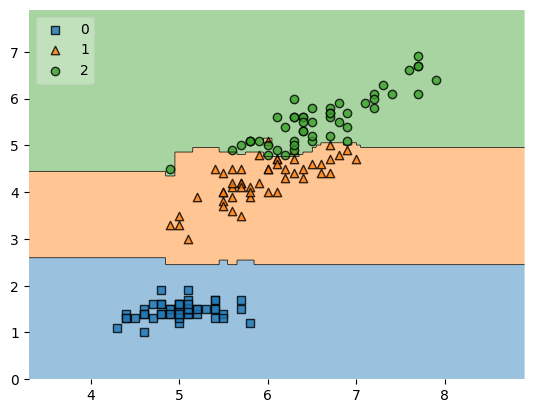

In [32]:
fig = plt.figure()
ax = plt.subplot()
fig = plot_decision_regions(X=X, y=y, clf = randfor_res, legend = 2)

In [33]:
confusion_matrix = metrics.confusion_matrix(y, randfor_res.predict(X))
confusion_matrix

array([[50,  0,  0],
       [ 0, 49,  1],
       [ 0,  0, 50]])

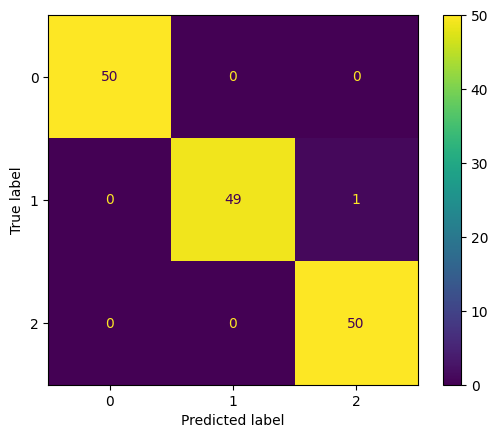

In [34]:
plot_confusion_matrix = metrics.ConfusionMatrixDisplay(confusion_matrix)
plot_confusion_matrix.plot()

### Ensemble

Es können aber auch unterschiedliche Arten von Submodellen zusammengeführt werden. Im folgenden Beispiel werden die Logistic Regression, das SVM-Modell und der Random Forest kombiniert:

In [35]:
# Generiere die "leeren" Modelle, die im Ensemble verwendet werden sollen
clf1 = LogisticRegression(random_state=0)
clf2 = RandomForestClassifier(random_state=0)
clf3 = SVC(random_state=0, probability=True)

# Füge die Modelle zusammen und gewichte sie
ensemble_res = EnsembleVoteClassifier(clfs=[clf1, clf2, clf3],
                              weights=[2, 1, 1],
                              voting='soft')

ensemble_res = ensemble_res.fit(X, y)

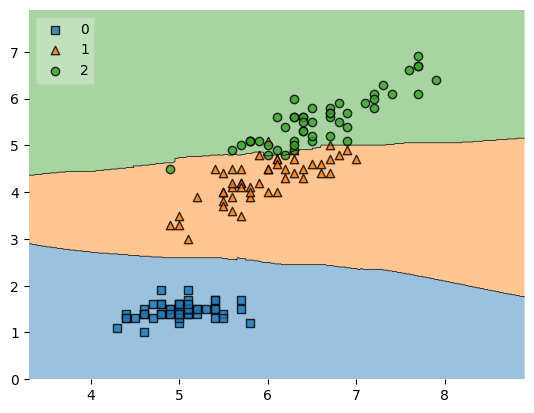

In [36]:
fig = plt.figure()
ax = plt.subplot()
fig = plot_decision_regions(X=X, y=y, clf = ensemble_res, legend = 2)

In [37]:
confusion_matrix = metrics.confusion_matrix(y, ensemble_res.predict(X))
confusion_matrix

array([[50,  0,  0],
       [ 0, 48,  2],
       [ 0,  1, 49]])

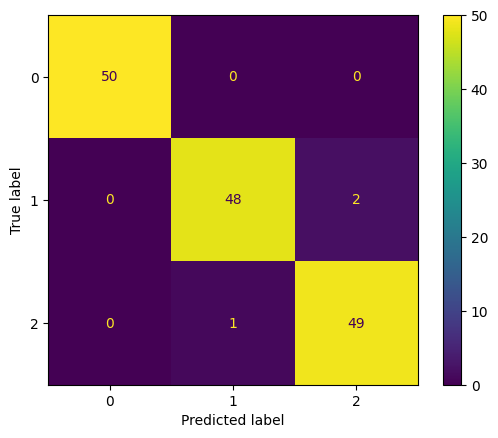

In [38]:
plot_confusion_matrix = metrics.ConfusionMatrixDisplay(confusion_matrix)
plot_confusion_matrix.plot()

## Neuronale Netze

In [40]:
# Normalisiere die Input-Daten
X = normalize(X, axis=0, norm='max')

# Ändere das Datenformat
X = X.astype(np.float32) 
y = y.astype(np.float32)

In [42]:
# Reduziere das Modell auf zwei Klassen
pos = y != 1
X = X[pos]
y = y[pos]

In [44]:
# Spezifiziere die Anzahl der Input- und Output-Knoten
input_dim = 2 # Anzahl der Input-Knoten -> x- u. y-Achse
output_dim = 1 # Anzahl der Output-Knoten -> Label: 0, 1

# Definiere die Input Variablen
W = tf.Variable(initial_value = tf.random.uniform(shape = (input_dim, output_dim)))
b = tf.Variable(initial_value = tf.zeros(shape = (output_dim,)))

In [45]:
# Definiere das Modell
def model(inputs):
    return tf.matmul(inputs, W) + b # a*W + b

In [46]:
# Definiere die Loss-Funktion
def square_loss(targets, predictions):
    per_sample_losses = tf.square(targets - predictions)
    return tf.reduce_mean(per_sample_losses)

In [47]:
# Definiere den Lern-Algorithmus
learning_rate = 0.1

def training_step(inputs, targets):
    with tf.GradientTape() as tape:
        predictions = model(inputs) # Mache Vorschlag (Predictions)
        loss = square_loss(predictions, targets) # Berechne Loss, d.h. vergleiche Predictions mit tatsächlichen Werten
    grad_loss_wrt_W, grad_loss_wrt_b = tape.gradient(loss, [W, b]) # Berechne Gradient
    W.assign_sub(grad_loss_wrt_W * learning_rate) # Update W
    b.assign_sub(grad_loss_wrt_b * learning_rate) # Update b
    return loss

In [48]:
# Training
for step in range(40):
    loss = training_step(X, y)
    print(f"Loss at step {step}: {loss:.4f}")

Loss at step 0: 1.6924
Loss at step 1: 1.2959
Loss at step 2: 1.1359
Loss at step 3: 1.0711
Loss at step 4: 1.0445
Loss at step 5: 1.0334
Loss at step 6: 1.0285
Loss at step 7: 1.0261
Loss at step 8: 1.0247
Loss at step 9: 1.0238
Loss at step 10: 1.0230
Loss at step 11: 1.0223
Loss at step 12: 1.0217
Loss at step 13: 1.0211
Loss at step 14: 1.0205
Loss at step 15: 1.0199
Loss at step 16: 1.0194
Loss at step 17: 1.0188
Loss at step 18: 1.0183
Loss at step 19: 1.0178
Loss at step 20: 1.0173
Loss at step 21: 1.0168
Loss at step 22: 1.0164
Loss at step 23: 1.0159
Loss at step 24: 1.0155
Loss at step 25: 1.0151
Loss at step 26: 1.0146
Loss at step 27: 1.0142
Loss at step 28: 1.0138
Loss at step 29: 1.0135
Loss at step 30: 1.0131
Loss at step 31: 1.0127
Loss at step 32: 1.0124
Loss at step 33: 1.0120
Loss at step 34: 1.0117
Loss at step 35: 1.0114
Loss at step 36: 1.0111
Loss at step 37: 1.0108
Loss at step 38: 1.0105
Loss at step 39: 1.0102


In [49]:
# Zeige die Vorhersagen des Modells an
predictions = model(X)
predictions

<tf.Tensor: shape=(100, 1), dtype=float32, numpy=
array([[0.89818215],
       [0.88725007],
       [0.8739315 ],
       [0.8732385 ],
       [0.89271617],
       [0.9217399 ],
       [0.870852  ],
       [0.8951027 ],
       [0.8599199 ],
       [0.88963664],
       [0.9169668 ],
       [0.8865571 ],
       [0.881784  ],
       [0.8472942 ],
       [0.93167144],
       [0.933365  ],
       [0.9121938 ],
       [0.89818215],
       [0.938138  ],
       [0.9005687 ],
       [0.9217399 ],
       [0.9005687 ],
       [0.86130583],
       [0.90534174],
       [0.8937167 ],
       [0.8974892 ],
       [0.8974892 ],
       [0.90603477],
       [0.90364826],
       [0.88109106],
       [0.8865571 ],
       [0.9169668 ],
       [0.90603477],
       [0.9200463 ],
       [0.88963664],
       [0.8879431 ],
       [0.9176598 ],
       [0.88725007],
       [0.85753334],
       [0.9005687 ],
       [0.8903296 ],
       [0.86299944],
       [0.85753334],
       [0.8974892 ],
       [0.9101148 ],
     

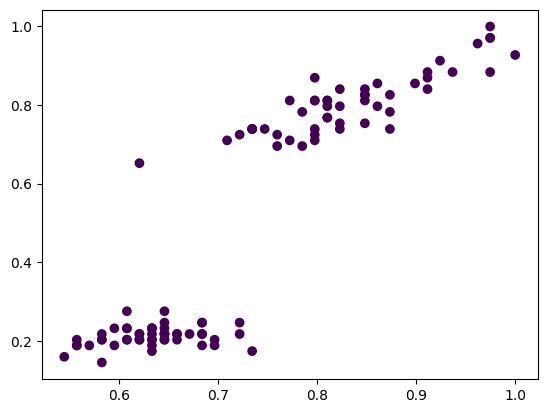

In [50]:
plt.scatter(X[:, 0], X[:, 1], c = predictions[:, 0] > 0.5)
plt.show()

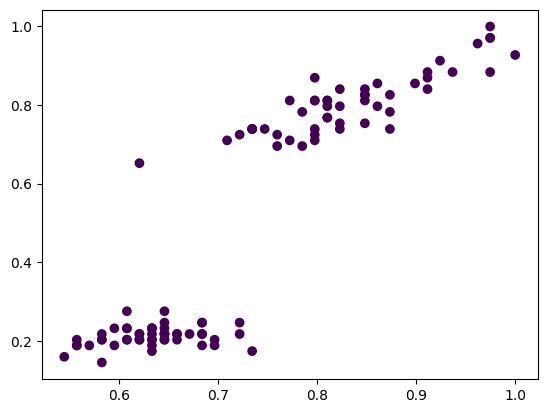

In [52]:
plt.scatter(X[:, 0], X[:, 1], c = predictions[:, 0] > 0.8)
plt.show()

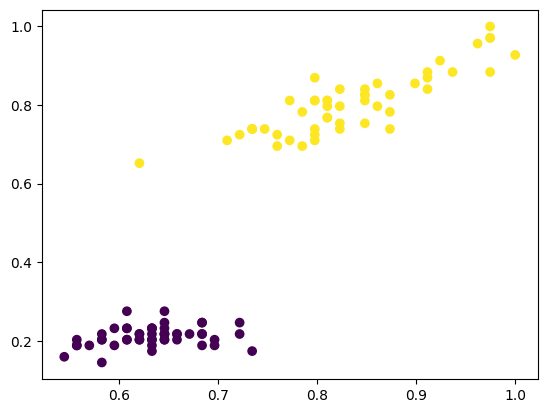

In [54]:
plt.scatter(X[:, 0], X[:, 1], c = predictions[:, 0] > 0.95)
plt.show()

## Quellen

* https://scikit-learn.org/1.5/auto_examples/datasets/plot_iris_dataset.html
* https://scikit-learn.org/1.5/modules/tree.html
* https://rasbt.github.io/mlxtend/